# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: de Vera, Clarence Joseph
- _Student No._: 2024-11757
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

#### Explain the figures.

The log-log plots show how absolute error drops as $n$ increases. For $f(x) = -x^2 + 1$, Simpson’s 1/3 and 3/8 rules flatline at machine precision ($\approx 10^{-15}$) immediately because Simpson's methods use quadratic curves, making them exact for 2nd-degree polynomials. For $\sqrt{9-4x^2}$ and $\sqrt{x}\cos(x)$, Simpson's rules offer no advantage over the Trapezoidal rule and their error lines overlap. This happens because both functions have infinite derivatives at their boundaries ($x=1.5$ and $x=0$), which breaks the error scaling assumption of Simpson's method. Monte Carlo error drops much more slowly and shows high random variation. The scatter plots display the sampled points, where blue dots mark area above the x-axis and red dots mark area below it.

#### Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?

Monte Carlo simulation calculates an integral using probability ratios. Random points are generated inside a bounding box of known total area. The fraction of points falling between the curve and the x-axis is multiplied by the total box area to calculate the integral. Newton-Cotes methods (Trapezoid and Simpson's) are more appropriate for smooth 1D functions because systematic polynomial approximations reach high accuracy with very few points. Monte Carlo is preferred for high-dimensional integrals (such as 4D or higher) where creating a standard grid requires too many grid points for a computer to process efficiently.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



Integral Answers Check
Function: sqrt(9 - 4x^2)
scipy quad:  3.53429174
trapezoid:   3.53424984
Simpson 1/3: 3.53427540
Simpson 3/8: 3.53427181
Monte Carlo: 3.52350000
Function: -x^2 + 1
scipy quad:  -1.33333333
trapezoid:   -1.33334402
Simpson 1/3: -1.33333333
Simpson 3/8: -1.33333333
Monte Carlo: -1.13439886
Function: sqrt(x)cos(x)
scipy quad:  -0.89483147
trapezoid:   -0.89486836
Simpson 1/3: -0.89484576
Simpson 3/8: -0.89484890
Monte Carlo: -0.86389769


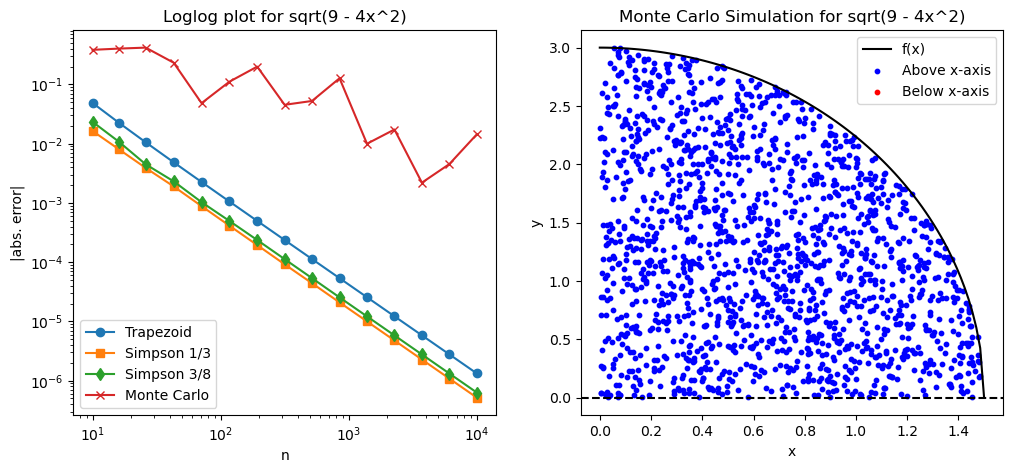

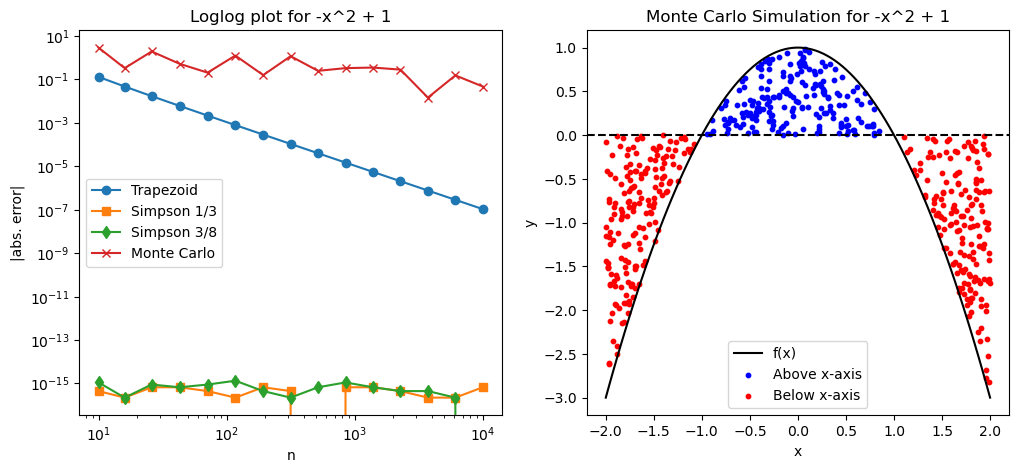

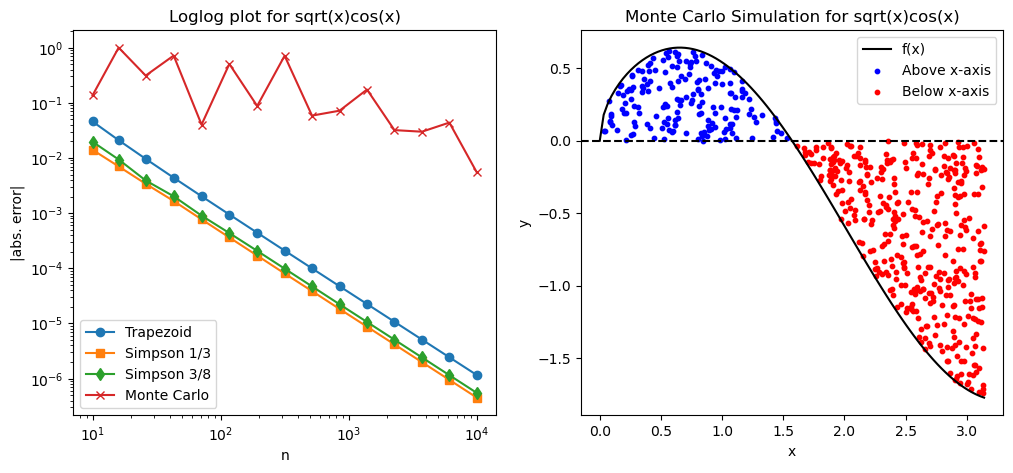

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.integrate as integrate

def monte_carlo(f, a, b, n):
    x_test = np.linspace(a, b, 1000)
    y_test = f(x_test)
    ymin = min(0, np.min(y_test))
    ymax = max(0, np.max(y_test))
    
    x_rand = np.random.uniform(a, b, n)
    y_rand = np.random.uniform(ymin, ymax, n)
    y_curve = f(x_rand)
    
    above = (y_rand >= 0) & (y_rand <= y_curve)
    below = (y_rand <= 0) & (y_rand >= y_curve)
    
    box_area = (b - a) * (ymax - ymin)
    frac_above = np.sum(above) / n
    frac_below = np.sum(below) / n
    
    total_area = box_area * (frac_above + frac_below)
    integral = box_area * (frac_above - frac_below)
    
    return total_area, integral, x_rand, y_rand, above, below

def trapezoid(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    
    cs = np.ones(n)
    cs[0] = 0.5 
    cs[-1] = 0.5
    
    contribs_int = cs * f(xs)
    contribs_area = cs * np.abs(f(xs))
    
    return h * np.sum(contribs_area), h * np.sum(contribs_int)

def simpson_13(f, a, b, n):
    if n % 2 == 0: 
        n += 1 
        
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    
    cs = 2 * np.ones(n)
    cs[1::2] = 4 
    cs[0] = 1 
    cs[-1] = 1
    
    contribs_int = cs * f(xs)
    contribs_area = cs * np.abs(f(xs))
    
    return (h / 3) * np.sum(contribs_area), (h / 3) * np.sum(contribs_int)

def simpson_38(f, a, b, n):
    while (n - 1) % 3 != 0: 
        n += 1
        
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    
    cs = 3 * np.ones(n)
    cs[0] = 1
    cs[-1] = 1
    cs[3:-1:3] = 2 
    
    contribs_int = cs * f(xs)
    contribs_area = cs * np.abs(f(xs))
    
    return (3 * h / 8) * np.sum(contribs_area), (3 * h / 8) * np.sum(contribs_int)


def f1(x): return np.sqrt(np.maximum(0, 9 - 4*x**2))
def f2(x): return -x**2 + 1
def f3(x): return np.sqrt(x) * np.cos(x)
funcs = [f1, f2, f3]
bounds = [(0, 1.5), (-2, 2), (0, np.pi)]
eqns = ["sqrt(9 - 4x^2)", "-x^2 + 1", "sqrt(x)cos(x)"]

# integral answers check
print("Integral Answers Check")
for i in range(3):
    f = funcs[i]
    a, b = bounds[i]
    
    true_int, _ = integrate.quad(f, a, b)
    _, int_trap = trapezoid(f, a, b, 1000)
    _, int_s13 = simpson_13(f, a, b, 1000)
    _, int_s38 = simpson_38(f, a, b, 1000)
    _, int_mc, _, _, _, _ = monte_carlo(f, a, b, 10000)
    
    print(f"Function: {eqns[i]}")
    print(f"scipy quad:  {true_int:.8f}")
    print(f"trapezoid:   {int_trap:.8f}")
    print(f"Simpson 1/3: {int_s13:.8f}")
    print(f"Simpson 3/8: {int_s38:.8f}")
    print(f"Monte Carlo: {int_mc:.8f}")

# plotting
n_vals = np.logspace(1, 4, 15).astype(int)

for i in range(3):
    f = funcs[i]
    a, b = bounds[i]
    eqn = eqns[i]
    
    true_int, _ = integrate.quad(f, a, b)
    
    err_trap, err_s13, err_s38, err_mc = [], [], [], []
    
    for n in n_vals:
        _, i_trap = trapezoid(f, a, b, n)
        _, i_s13 = simpson_13(f, a, b, n)
        _, i_s38 = simpson_38(f, a, b, n)
        _, i_mc, _, _, _, _ = monte_carlo(f, a, b, n)
        
        err_trap.append(np.abs(i_trap - true_int))
        err_s13.append(np.abs(i_s13 - true_int))
        err_s38.append(np.abs(i_s38 - true_int))
        err_mc.append(np.abs(i_mc - true_int))
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    ax1.plot(n_vals, err_trap, 'o-', label='Trapezoid')
    ax1.plot(n_vals, err_s13, 's-', label='Simpson 1/3')
    ax1.plot(n_vals, err_s38, 'd-', label='Simpson 3/8')
    ax1.plot(n_vals, err_mc, 'x-', label='Monte Carlo')
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlabel('n')
    ax1.set_ylabel('|abs. error|')
    ax1.set_title(f'Loglog plot for {eqn}')
    ax1.legend()
    
    _, _, x_rand, y_rand, above, below = monte_carlo(f, a, b, 2000)
    
    x_line = np.linspace(a, b, 100)
    ax2.plot(x_line, f(x_line), color='black', label='f(x)')
    ax2.axhline(0, color='black', linestyle='--')
    
    ax2.scatter(x_rand[above], y_rand[above], color='blue', s=10, label='Above x-axis')
    ax2.scatter(x_rand[below], y_rand[below], color='red', s=10, label='Below x-axis')
    
    ax2.set_xlabel('x')
    ax2.set_ylabel('y')
    ax2.set_title(f'Monte Carlo Simulation for {eqn}')
    ax2.legend()
    
    plt.show()